[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adkipnis/metabeta/blob/main/demos/02-families.ipynb)

# likelihood families

metabeta ships one pretrained checkpoint per likelihood family. This notebook fits two of them:

- **Bernoulli**: infections in cattle herds (lme4's `cbpp`).
- **Poisson**: salamander counts in streams (glmmTMB's `Salamanders`).

In [ ]:
%pip install -q metabeta==0.5.1 pyreadr

## Load the checkpoints

In [1]:
import numpy as np
import pandas as pd
import pyreadr  # reads R data files, no R needed
import statsmodels.api as sm
import torch

from metabeta import Api

device = 'cuda' if torch.cuda.is_available() else 'cpu'
mb_bernoulli = Api.from_pretrained('bernoulli', device=device)
mb_poisson = Api.from_pretrained('poisson', device=device)

Resolving metabeta 'bernoulli' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-bernoulli.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


Resolving metabeta 'poisson' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-poisson.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


## Binary outcomes

`cbpp` ([Lesnoff et al., 2004](https://doi.org/10.1016/j.prevetmed.2004.03.005)) follows 15
Ethiopian cattle herds through an outbreak of contagious bovine pleuropneumonia:

- **Outcome**: each animal either became a new case or not, so the outcome is binary.
- **Groups**: animals of one herd share their conditions, so each herd gets its own intercept.
- **Predictor**: the observation period, one of four.

In [2]:
cbpp = sm.datasets.get_rdataset('cbpp', 'lme4').data
rows = cbpp.loc[cbpp.index.repeat(cbpp['size'])]  # counts per herd and period → one row per animal
df_cbpp = pd.DataFrame(
    {
        # the first `incidence` animals of each herd and period are new cases, the rest are not
        'infected': (rows.groupby(level=0).cumcount() < rows['incidence']).astype(int).to_numpy(),
        'period': rows['period'].astype(str).to_numpy(),  # a category, not a number
        'herd': rows['herd'].astype(str).to_numpy(),  # a label, not a number
    }
)
herd_sizes = df_cbpp.groupby('herd').size()
print(f'{len(df_cbpp)} rows, {len(herd_sizes)} herds with {herd_sizes.min()}–{herd_sizes.max()} rows each')
df_cbpp.head()

842 rows, 15 herds with 26–96 rows each


,infected,period,herd
0,1,1,1
1,1,1,1
2,0,1,1
3,0,1,1
4,0,1,1


### Fit

In [3]:
%%time
torch.manual_seed(0)  # for reproducibility
result_cbpp = mb_bernoulli.sample(
    df_cbpp, formula='infected ~ period + (1 | herd)',
    n_samples=2000,  # at the default 1000, the effective sample size (ESS) nears its threshold
)

CPU times: user 819 ms, sys: 31.5 ms, total: 851 ms
Wall time: 369 ms


### Posterior summary

- **Intercept**: the log-odds of infection in period 1, for an average herd.
- **`period_2` to `period_4`**: the change in log-odds from period 1. All three are negative:
  infections drop after the first period.
- **AUC** (last line): the chance that a random infected animal gets a higher predicted
  probability than a random healthy one. 0.5 is chance, 1 is perfect.

In [4]:
print(mb_bernoulli.posteriorSummary(result_cbpp))

Formula:  infected ~ period + (1 | herd)
n = 842   m = 15
Priors:
  Intercept ~ N(0, 1.5)
  period_2 ~ N(0, 1)
  period_3 ~ N(0, 1)
  period_4 ~ N(0, 1)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept | -1.430 | 0.255 | -1.972 |  -1.442 |  -0.983 |   0.000 |    0.971 |
| period_2  | -0.875 | 0.290 | -1.428 |  -0.878 |  -0.300 |   0.002 |    0.916 |
| period_3  | -0.998 | 0.312 | -1.631 |  -0.992 |  -0.401 |   0.000 |    0.903 |
| period_4  | -1.341 | 0.384 | -2.198 |  -1.304 |  -0.700 |   0.000 |    0.852 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.780 | 0.234 |  0.416 |   0.751 |   1.312 |

draws = 2000   acceptance = 0.36   min ESS = 162   PSIS k̂ = 0.132 (refined)   MAP z = 0.5   AUC = 0.750


### Posterior predictive check

`plotPPD` compares the observed outcomes (black) with outcomes replicated from the posterior
(green: median and 95% band).<br>
The black curve lies inside the band at both peaks, healthy on the left and infected on the right,
so the model reproduces the infection rate.

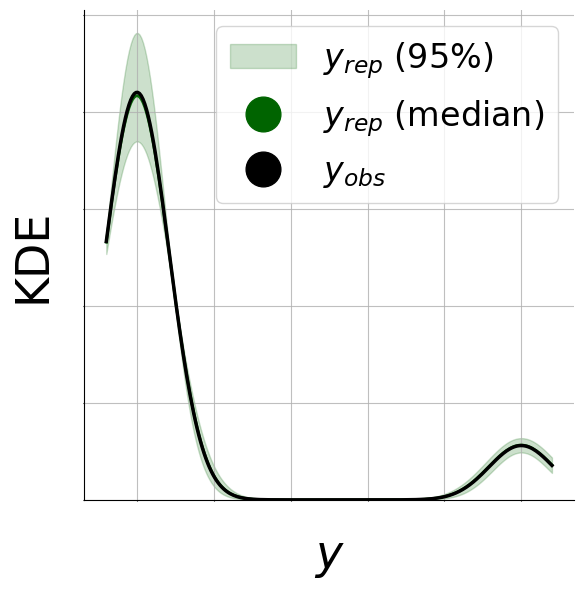

In [5]:
mb_bernoulli.plotPPD(result_cbpp)

## Count outcomes

`Salamanders` ([Price et al., 2016](https://doi.org/10.1111/1365-2664.12585)) counts salamanders
in 23 Appalachian streams. Some streams lie below mountaintop-removal mines (`mined`).

In [6]:
pyreadr.download_file('https://github.com/glmmTMB/glmmTMB/raw/1db3b4692aa4c61ae5c9974b32b9f91555cf5f2c/glmmTMB/data/Salamanders.rda', 'Salamanders.rda')
salamanders = pyreadr.read_r('Salamanders.rda')['Salamanders']
# Wtemp (water temperature) is unused here; try it as a random slope
df_sal = salamanders[['count', 'mined', 'Wtemp', 'site']].astype({'mined': str, 'site': str})
print(f'{len(df_sal)} rows in {df_sal["site"].nunique()} sites')
df_sal.head()

644 rows in 23 sites


,count,mined,Wtemp,site
0,0,yes,-1.229379,VF-1
1,0,yes,0.084765,VF-2
2,0,yes,1.014176,VF-3
3,2,no,-3.023358,R-1
4,2,no,-0.144345,R-2


### Fit with the defaults

This time, `sample` warns:

1. The independence Metropolis–Hastings (IMH) chains can only jump between the network's draws.
2. Here they accept few jumps, so they often repeat a draw.
3. So the ESS falls below its threshold, and the intervals can come out too narrow.

More draws, the first remedy, don't help here, so we try the second below.

In [7]:
%%time
torch.manual_seed(0)
result_imh = mb_poisson.sample(df_sal, formula='count ~ mined + (1 | site)')

CPU times: user 247 ms, sys: 16 ms, total: 263 ms
Wall time: 183 ms


<timed exec>:2: UserWarning: Low effective sample size (ESS) for dataset(s) [0]: min ESS 26 < 150.
The IMH chains repeat few draws, so the intervals can be too narrow. Remedies, in order:
  1. more draws (n_samples)
  2. random_walk=True
  3. exact MCMC, e.g. NUTS


- **Intercept**: the log of the expected count at an unmined site.
- **`mined_yes`**: the log of the count ratio, mined over unmined. A mean of −2.30 means about a
  tenth of the salamanders at mined sites.
- **Deviance** (last line): how far the counts fall from the predicted rates. Lower is better.

In [8]:
print(mb_poisson.posteriorSummary(result_imh))

Formula:  count ~ mined + (1 | site)
n = 644   m = 23
Priors:
  Intercept ~ N(0, 2.5)
  mined_yes ~ N(0, 2.5)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept |  0.780 | 0.173 |  0.476 |   0.762 |   1.074 |   1.000 |    0.995 |
| mined_yes | -2.304 | 0.320 | -2.945 |  -2.307 |  -1.751 |   0.000 |    0.984 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.685 | 0.185 |  0.446 |   0.653 |   1.201 |

draws = 1000   acceptance = 0.17   min ESS = 26   PSIS k̂ = 0.590 (refined)   MAP z = 0.4   Deviance = 2.201


### With random-walk moves

`random_walk=True` continues the IMH chains with random-walk moves:

- The moves can step off the network's draws, into regions the network misses.
- They run only where the ESS is below its threshold, so the flag is safe to pass by default.

In [9]:
torch.manual_seed(0)
result_rw = mb_poisson.sample(df_sal, formula='count ~ mined + (1 | site)', random_walk=True)
print(mb_poisson.posteriorSummary(result_rw))

Formula:  count ~ mined + (1 | site)
n = 644   m = 23
Priors:
  Intercept ~ N(0, 2.5)
  mined_yes ~ N(0, 2.5)
  σ_Intercept ~ HN(2.5)

Fixed Effects:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|--------|-------|--------|---------|---------|---------|----------|
| Intercept |  0.726 | 0.195 |  0.330 |   0.729 |   1.105 |   1.000 |    0.994 |
| mined_yes | -2.246 | 0.327 | -2.884 |  -2.247 |  -1.641 |   0.000 |    0.983 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept |  0.679 | 0.166 |  0.430 |   0.647 |   1.073 |

draws = 1000   acceptance = 0.17   min ESS = 26 (random-walk moves ran)   PSIS k̂ = 0.590 (refined)   MAP z = 0.4   Deviance = 2.201


### Intervals

We compare the 95% intervals with exact Markov chain Monte Carlo (MCMC): PyMC's No-U-Turn
Sampler (NUTS) on the same model and priors. NUTS doesn't run here, so its intervals are
hard-coded.

- **Intercept**: IMH alone spans 0.70 of NUTS's width. The moves bring it to 0.91.
- **`mined_yes`**: barely changes, from 0.90 to 0.94 of NUTS's width.

In [10]:
# NUTS via metabeta.utils.pymc.buildPymc (needs metabeta[research]): 4 chains × 1000 draws
# after 1000 tuning steps, no divergences, max r-hat 1.004
nuts = pd.DataFrame(
    {'mean': [0.737, -2.270], '2.5%': [0.310, -2.965], '97.5%': [1.159, -1.640]},
    index=['Intercept', 'mined_yes'],
)


def intervals(result):
    draws = mb_poisson.posteriorDraws(result)[nuts.index]  # in the data's units, as in the summaries
    return pd.DataFrame(
        {'mean': draws.mean(), '2.5%': draws.quantile(0.025), '97.5%': draws.quantile(0.975)}
    )


table = pd.concat(
    {'IMH': intervals(result_imh), 'IMH + moves': intervals(result_rw), 'NUTS': nuts},
    names=['method', 'parameter'],
)
table = table.swaplevel().sort_index(level='parameter', sort_remaining=False)
table['95% width'] = table['97.5%'] - table['2.5%']
table['width / NUTS'] = table['95% width'] / table['95% width'].xs('NUTS', level='method')
table.round(2)

mean  2.5%  97.5%  95% width  width / NUTS
parameter method                                                 
Intercept IMH          0.78  0.48   1.07       0.60          0.70
          IMH + moves  0.73  0.33   1.11       0.78          0.91
          NUTS         0.74  0.31   1.16       0.85          1.00
mined_yes IMH         -2.30 -2.94  -1.75       1.19          0.90
          IMH + moves -2.25 -2.88  -1.64       1.24          0.94
          NUTS        -2.27 -2.96  -1.64       1.32          1.00

### Posterior predictive check

For counts, a few statistics say more than a density plot:

In [11]:
y_obs = df_sal['count'].to_numpy()[:, None]                    # (n, 1)
mask = result_rw.batch['mask_n'][0].bool()                    # (m, rows per site) real rows
y_rep = result_rw.diagnostics['pp'].sample()[0][mask].numpy()  # (n, S) one replicate per draw


def stats(y):  # median over draws
    return {
        'mean': np.median(y.mean(0)),
        'variance': np.median(y.var(0)),
        'share of zeros': np.median((y == 0).mean(0)),
        'largest count': np.median(y.max(0)),
    }


pd.DataFrame({'observed': stats(y_obs), 'replicated': stats(y_rep)}).round(2)

,observed,replicated
mean,1.32,1.32
variance,6.94,2.62
share of zeros,0.60,0.44
largest count,36.00,9.00


The model matches the mean but not the spread: the observed counts have more zeros and a longer
tail. [Brooks et al. (2017)](https://doi.org/10.32614/RJ-2017-066) fit zero-inflated and negative
binomial models for this, which metabeta doesn't currently support, so the gap is the model's, not
the sampler's.

## When `sample` warns

Each warning lists its remedies. `result.safeguards` holds the checks behind them, here for the
default fit:

In [12]:
sg = result_imh.safeguards
pd.DataFrame(
    {
        'value': [sg['accept_rate'][0], sg['ess_min'][0], sg['map_z'][0]],
        'warns if': ['below', 'below', 'above'],
        'threshold': [sg['accept_threshold'], sg['ess_threshold'], sg['map_z_threshold']],
        'flagged': [sg['accept_flag'][0], sg['ess_flag'][0], sg['map_z_flag'][0]],
    },
    index=['acceptance', 'min ESS', 'MAP z'],
).round(2)

,value,warns if,threshold,flagged
acceptance,0.17,below,0.1,False
min ESS,25.89,below,150.0,True
MAP z,0.43,above,5.0,False


## Next steps

- `03-priors`: custom priors and Bayes factors.